In [1]:
'''
Yeah we're gonna just remove them for now, later we can analyze them
or i guess we can start by figuring out how many we have
'''

"\nYeah we're gonna just remove them for now, later we can analyze them\n"

In [1]:
import numpy as np
import pandas as pd
from astropy.io import fits
import matplotlib.pyplot as plt
import scipy.ndimage as snm

In [2]:
import plot_time_series as pts
import precision_recall as pr
import importlib
#importlib.reload(plot_time_series)
import gc #garbage collector
import glob #i don't know if there is a better way to do this but this was the 
#internet's suggestion for searching with an incomplete path name
import review_findings_functions as rff
import os
import implantation_functions as imp
from scipy.signal import find_peaks
import fitting as fitting

In [3]:
plt.rcParams["figure.figsize"] = (10, 7)
plt.rcParams["image.interpolation"] = "nearest"
plt.rcParams["image.cmap"] = "gist_gray"

In [4]:
df_lessthan13 = pd.read_csv('/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/df_lessthan13')

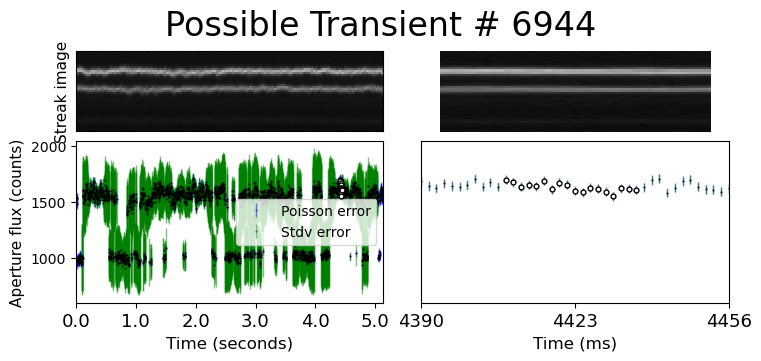

In [14]:
rff.plot_time_series_again_aperture(df_lessthan13, 6944)



In [5]:
df_lessthan13

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
0,0,0,0,3,3,ztf_20221020297847_000449_zr_c05_x_0006.,pos,627.166667,559.333333,6.0,4,12.891250,1.303873,1.792471,-1.921662
1,1,1,1,4,4,ztf_20221020297847_000449_zr_c05_x_0006.,pos,655.625000,1208.750000,8.0,4,12.620198,3.551599,3.661652,-3.093721
2,2,2,2,8,8,ztf_20221020297847_000449_zr_c05_x_0006.,pos,1834.833333,560.916667,12.0,4,7.786941,2.971391,2.971391,-1.201024
3,3,3,3,12,12,ztf_20221020297847_000449_zr_c05_x_0006.,pos,2343.333333,1209.500000,12.0,4,9.809223,3.095683,3.140310,-0.995967
4,4,4,4,25,25,ztf_20221020297847_000449_zr_c05_x_0006.,neg,647.000000,1209.928571,14.0,4,12.620198,-1.530615,3.552551,-3.001541
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
610668,610898,263,263,551,551,ztf_20221020297847_000449_zr_c14_x_0026.,both,2923.142857,1320.428571,7.0,4,9.755448,0.476716,1.637385,-1.839140
610669,610899,264,264,552,552,ztf_20221020297847_000449_zr_c14_x_0026.,both,2937.153846,1320.692308,13.0,4,11.997117,0.194553,0.760646,-1.656184
610670,610900,265,265,554,554,ztf_20221020297847_000449_zr_c14_x_0026.,both,2951.500000,1321.416667,12.0,4,14.919274,-0.671413,0.720585,-1.495678
610671,610901,266,266,555,555,ztf_20221020297847_000449_zr_c14_x_0026.,both,2952.000000,1326.000000,9.0,4,14.998910,-1.493181,0.719382,-1.493181


In [6]:
df_lessthan13_morethanfive_pos = df_lessthan13[df_lessthan13['snr_max']>5]

In [7]:
df_lessthan13_morethanfive_neg = df_lessthan13[df_lessthan13['snr_min']<-5]

In [27]:
len(df_lessthan13_morethanfive_neg)

2415

In [19]:
df_lessthan13_morethanfive

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
0,1226,42,42,671,671,ztf_20221020154120_000640_zi_c12_x_0003.,pos,1806.000000,2315.375000,8.0,4,11.291146,4.234775,5.398891,-0.186918
1,1586,402,402,2457,2457,ztf_20221020154120_000640_zi_c12_x_0003.,both,1806.000000,2315.375000,8.0,4,11.291146,4.234775,5.398891,-0.186918
2,1701,13,13,43,43,ztf_20221020148032_000686_zg_c16_x_0009.,pos,1861.142857,2324.285714,7.0,3,13.100600,2.633919,5.319937,-1.448824
3,1768,81,81,349,349,ztf_20221020148032_000686_zg_c16_x_0009.,both,1861.142857,2324.285714,7.0,3,13.100600,2.633919,5.319937,-1.448824
4,3004,12,12,28,28,ztf_20221020138241_000686_zi_c14_x_0004.,pos,2768.625000,699.437500,16.0,4,13.012238,4.796971,5.315604,0.825760
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3255,607181,231,231,1704,1704,ztf_20221020141806_000686_zi_c16_x_0007.,both,1021.200000,712.950000,20.0,4,7.404187,0.024185,0.764265,-5.152496
3256,608858,63,63,420,420,ztf_20221020297847_000449_zr_c15_x_0021.,neg,667.111111,2011.111111,9.0,4,14.148529,-2.747320,-0.564878,-5.583662
3257,608988,193,193,707,707,ztf_20221020297847_000449_zr_c15_x_0021.,both,667.111111,2011.111111,9.0,4,14.148529,-2.747320,-0.564878,-5.583662
3258,609280,145,145,705,705,ztf_20221020163819_000640_zg_c12_x_0010.,neg,3040.750000,616.750000,16.0,3,12.139935,-5.862447,-1.406711,-6.065737


In [8]:
df_lessthan13_morethanfive_pos_cleaned = df_lessthan13_morethanfive_pos.drop_duplicates(subset=['filename', 'row_from_nn', 'col_from_nn'])
df_lessthan13_morethanfive_neg_cleaned = df_lessthan13_morethanfive_neg.drop_duplicates(subset=['filename', 'row_from_nn', 'col_from_nn'])

In [34]:
len(df_lessthan13_morethanfive_neg_cleaned)

1248

In [29]:
len(df_lessthan13_morethanfive_pos_cleaned)

432

In [31]:
df_lessthan13_morethanfive_pos_cleaned

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
1226,1226,42,42,671,671,ztf_20221020154120_000640_zi_c12_x_0003.,pos,1806.000000,2315.375000,8.0,4,11.291146,4.234775,5.398891,-0.186918
1701,1701,13,13,43,43,ztf_20221020148032_000686_zg_c16_x_0009.,pos,1861.142857,2324.285714,7.0,3,13.100600,2.633919,5.319937,-1.448824
3004,3004,12,12,28,28,ztf_20221020138241_000686_zi_c14_x_0004.,pos,2768.625000,699.437500,16.0,4,13.012238,4.796971,5.315604,0.825760
6981,6981,1,1,7,7,ztf_20221020138241_000686_zi_c12_x_0017.,pos,1866.666667,371.866667,15.0,1,20.811592,2.126988,5.616586,-0.782699
10250,10250,0,0,4,4,ztf_20221020163819_000640_zg_c11_x_0013.,pos,216.692308,842.923077,13.0,2,18.695545,5.803694,5.803694,0.289374
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
596779,597009,78,78,193,193,ztf_20221020148032_000686_zg_c03_x_0018.,neg,1964.571429,1236.285714,21.0,2,21.395960,1.551655,5.411989,-0.396976
597542,597772,19,19,149,149,ztf_20221020157697_000640_zi_c10_x_0017.,pos,1895.500000,890.000000,6.0,4,12.870794,5.011562,5.011562,-0.936543
604213,604443,26,26,71,71,ztf_20221020148032_000686_zg_c06_x_0018.,neg,147.714286,1149.428571,7.0,2,13.669434,2.536304,5.922361,0.807002
606332,606562,88,88,454,454,ztf_20221020157697_000640_zi_c14_x_0019.,neg,2536.312500,1317.750000,16.0,4,12.239103,0.549143,5.037777,-2.834963


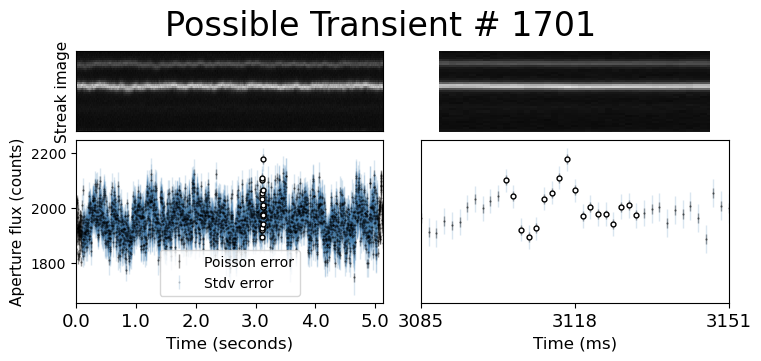

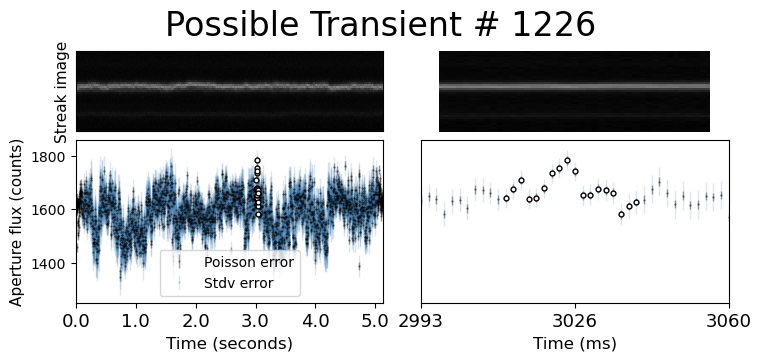

In [21]:
rff.plot_time_series_again_aperture(df_lessthan13_morethanfive_pos_cleaned, 1226)

In [ ]:
# -- note that there is a sobel filter in scipy.ndimage.filters as well
from scipy.ndimage import sobel

Lx=sobel(stamp,axis=1) #column axis
Ly=sobel(stamp,axis=0) #rows axis
LL=np.sqrt(Lx**2+Ly**2)

fig, ax = plt.subplots(1, 4)
st = ax[0].imshow(stamp)
# # ll = ax[1].imshow(LL>400)
# ll = ax[1].imshow(Ly)
# ax[1].set_title("sobel filter")
# ax[0].set_title("original image (probable cosmic ray)")
# fig.colorbar(ll)
# fig.colorbar(st)

lx = ax[1].imshow(Lx)
ly = ax[2].imshow(Ly)
ll = ax[3].imshow(LL)
ax[2].set_title("sobel filter in y")
ax[1].set_title("sobel filter in x")
ax[3].set_title("total sobel filter")
ax[0].set_title("cosmic ray")
fig.colorbar(ly)
fig.colorbar(lx)
fig.colorbar(ll)
fig.colorbar(st)

fig.show()

In [14]:
rff.get_stamp_from_df?

Signature: rff.get_stamp_from_df(index, direcname, df, norm=True)
Docstring:
returns a 20x20 numpy array of brightnesses centered around the detection
located at index of dataframe df
note that the filepath to the science images is hardcoded currently
norm=True has the image normalized (not the stamp, the entire image)
norm=False has it in terms of counts
File:      ~/review_findings_functions.py
Type:      function

In [17]:
np.shape(result)

(20, 20)

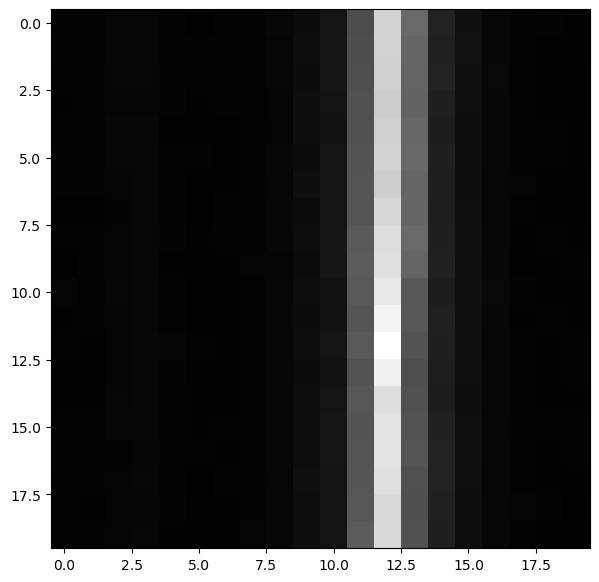

In [18]:
plt.imshow(result)

In [16]:
result = rff.get_stamp_from_df(6981, '1020', df_lessthan13_morethanfive_pos_cleaned)

In [5]:
path = '/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/ztf_20221020138241_000686_zi_c12_x_0017.fits.fz'
hdul = fits.open(path)

In [56]:
hdul[0].header

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                  -32 / number of bits per data pixel                  
NAXIS   =                    0 / number of data axes                            
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
ORIGIN  = 'Zwicky Transient Facility' / Data origin                             
OBSERVER= 'ZTF Robotic Observing Software' / Observer                           
ROBOSOFT= '1.1 August 1, 2022' / Robotic software version                       
FITSSOFT= '1.1 August 1, 2022' / FITS software version                          
INSTRUME= 'ZTF/MOSAIC'         / Instrument name                                
DETECTOR= '        '           / Detector controller                            
DETSOFT = '        '        

In [19]:
find_peaks?

Signature:
find_peaks(
    x,
    height=None,
    threshold=None,
    distance=None,
    prominence=None,
    width=None,
    wlen=None,
    rel_height=0.5,
    plateau_size=None,
)
Docstring:
Find peaks inside a signal based on peak properties.

This function takes a 1-D array and finds all local maxima by
simple comparison of neighboring values. Optionally, a subset of these
peaks can be selected by specifying conditions for a peak's properties.

Parameters
----------
x : sequence
    A signal with peaks.
height : number or ndarray or sequence, optional
    Required height of peaks. Either a number, ``None``, an array matching
    `x` or a 2-element sequence of the former. The first element is
    always interpreted as the  minimal and the second, if supplied, as the
    maximal required height.
threshold : number or ndarray or sequence, optional
    Required threshold of peaks, the vertical distance to its neighboring
    samples. Either a number, ``None``, an array matching `x` or

In [5]:
def has_two_streaks(df, index, direcname='1020'):
    '''
    will return true if it has two streaks, otherwise false
    '''
    fname = df.loc[index]["filename"]+"fits.fz"
    row = int(df.loc[index]["row_from_nn"])+10
    col = int(df.loc[index]["col_from_nn"])+10
    quad = int(df.loc[index]["quadrant"])
    # if direcname == "0820":
    fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"+direcname+"_minus_extras/"
    # else:
        # fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"+direcname+"/"
    path = fpath+fname
    # print(path)
    hdul = fits.open(path)
    file1_array = hdul[quad].data

    averages = np.average(file1_array[row-20:row+20, col-20:col+20], axis=0)
    plt.plot(averages)
    peaks, properties = find_peaks(averages, prominence=100)
    # print(peaks)
    # print(properties['prominences'])
    if len(peaks)>1:
        return True, properties
    else:
        return False

    


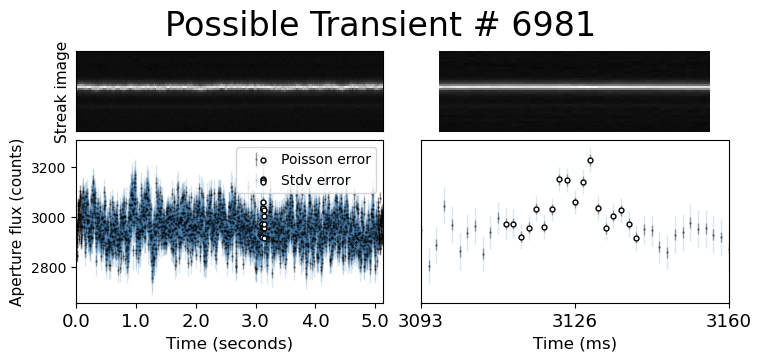

In [79]:
rff.plot_time_series_again_aperture(df_lessthan13_morethanfive_pos_cleaned, 6981, '1020',2, tracking=False)

In [ ]:
[1226, 1701, 3004, 6981, 13278

TypeError: cannot unpack non-iterable bool object

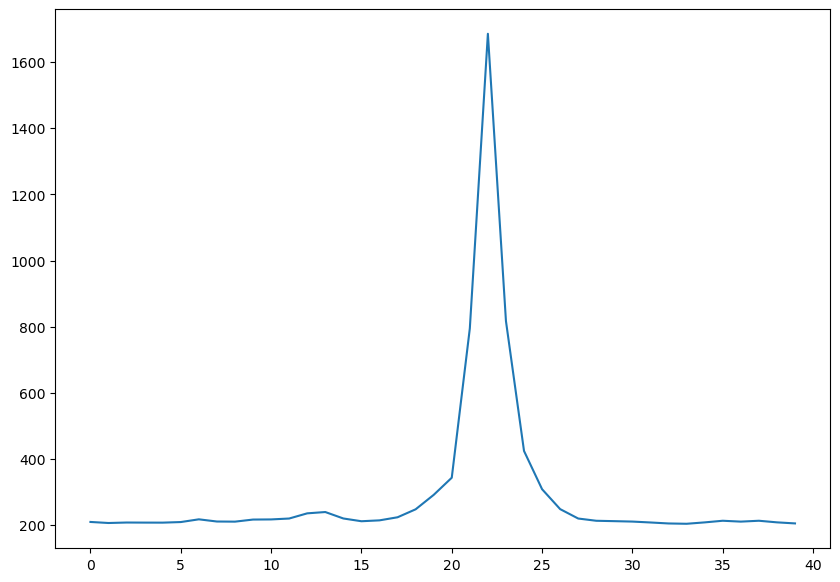

In [9]:
t, properties = has_two_streaks(df_lessthan13_morethanfive_pos_cleaned, 6981)
plt.yscale('log')

In [66]:
593/103

5.757281553398058

In [65]:
properties['prominences']

array([593.94911194, 103.90252686,  23.64572144])

In [31]:
df_lessthan13_morethanfive_pos_cleaned

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min
1226,1226,42,42,671,671,ztf_20221020154120_000640_zi_c12_x_0003.,pos,1806.000000,2315.375000,8.0,4,11.291146,4.234775,5.398891,-0.186918
1701,1701,13,13,43,43,ztf_20221020148032_000686_zg_c16_x_0009.,pos,1861.142857,2324.285714,7.0,3,13.100600,2.633919,5.319937,-1.448824
3004,3004,12,12,28,28,ztf_20221020138241_000686_zi_c14_x_0004.,pos,2768.625000,699.437500,16.0,4,13.012238,4.796971,5.315604,0.825760
6981,6981,1,1,7,7,ztf_20221020138241_000686_zi_c12_x_0017.,pos,1866.666667,371.866667,15.0,1,20.811592,2.126988,5.616586,-0.782699
10250,10250,0,0,4,4,ztf_20221020163819_000640_zg_c11_x_0013.,pos,216.692308,842.923077,13.0,2,18.695545,5.803694,5.803694,0.289374
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
596779,597009,78,78,193,193,ztf_20221020148032_000686_zg_c03_x_0018.,neg,1964.571429,1236.285714,21.0,2,21.395960,1.551655,5.411989,-0.396976
597542,597772,19,19,149,149,ztf_20221020157697_000640_zi_c10_x_0017.,pos,1895.500000,890.000000,6.0,4,12.870794,5.011562,5.011562,-0.936543
604213,604443,26,26,71,71,ztf_20221020148032_000686_zg_c06_x_0018.,neg,147.714286,1149.428571,7.0,2,13.669434,2.536304,5.922361,0.807002
606332,606562,88,88,454,454,ztf_20221020157697_000640_zi_c14_x_0019.,neg,2536.312500,1317.750000,16.0,4,12.239103,0.549143,5.037777,-2.834963


In [38]:
df_lessthan13_morethanfive_pos_cleaned.index

Int64Index([  1226,   1701,   3004,   6981,  10250,  13278,  14572,  14573,
             16707,  17098,
            ...
            581621, 583152, 586988, 591818, 591846, 596779, 597542, 604213,
            606332, 607092],
           dtype='int64', length=432)

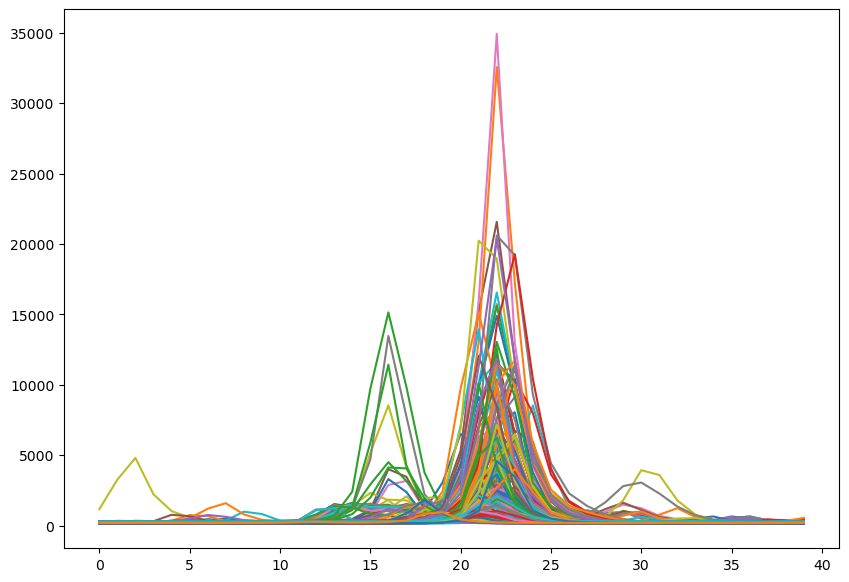

In [15]:
to_drop = []
for index in df_lessthan13_morethanfive_pos_cleaned.index:
    if has_two_streaks(df_lessthan13_morethanfive_pos_cleaned, index):
        to_drop.append(index)
    # if len(to_drop)==5:
    #     break

In [16]:
df_lessthan13_morethanfive_pos_cleaned_onestreak = df_lessthan13_morethanfive_pos_cleaned.drop(to_drop)

In [72]:
len(df_lessthan13_morethanfive_pos_cleaned_onestreak)

320

In [17]:
biggest = df_lessthan13_morethanfive_pos_cleaned_onestreak[df_lessthan13_morethanfive_pos_cleaned_onestreak['snr_max']>7]

In [83]:
len(biggest)

20

In [1]:
real_indices = [107085, ]

/home/3155/review_findings_functions.py:1138: RuntimeWarning: invalid value encountered in sqrt
  sqrt = np.sqrt(tot/6.2) #6.2 electrons per photon


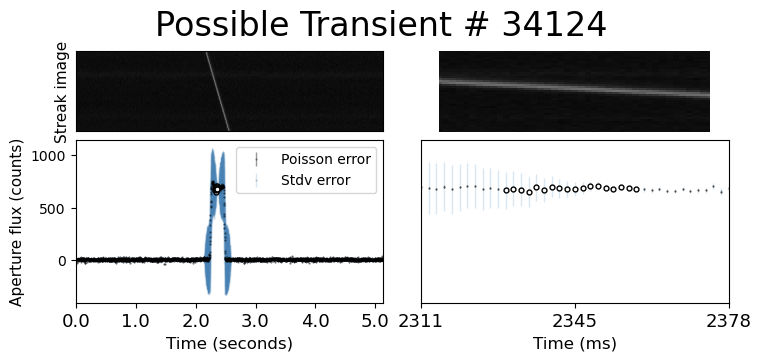

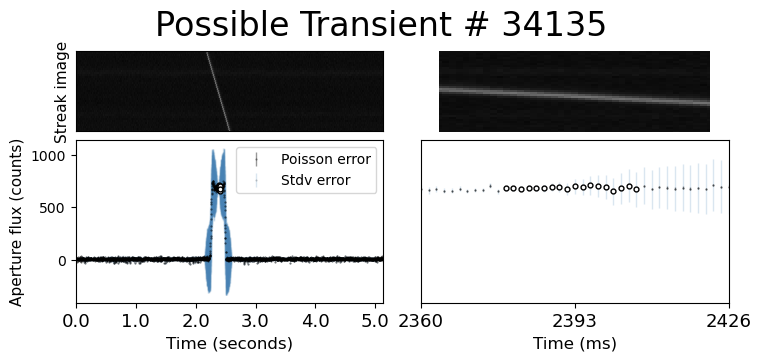

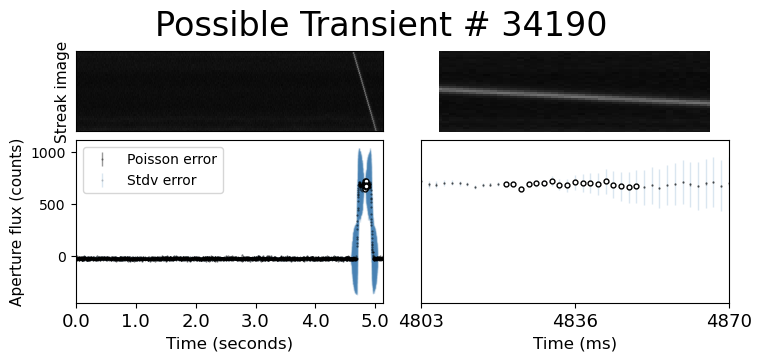

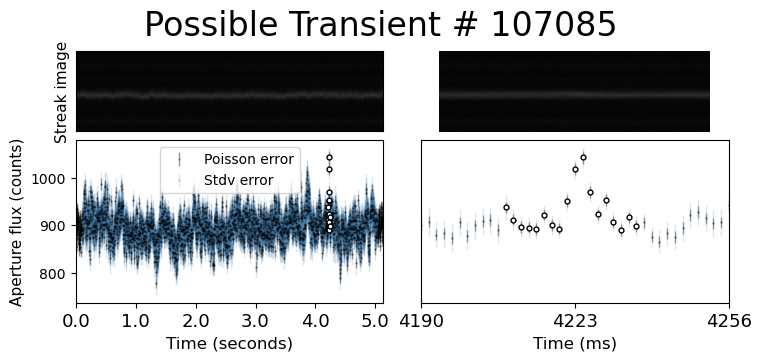

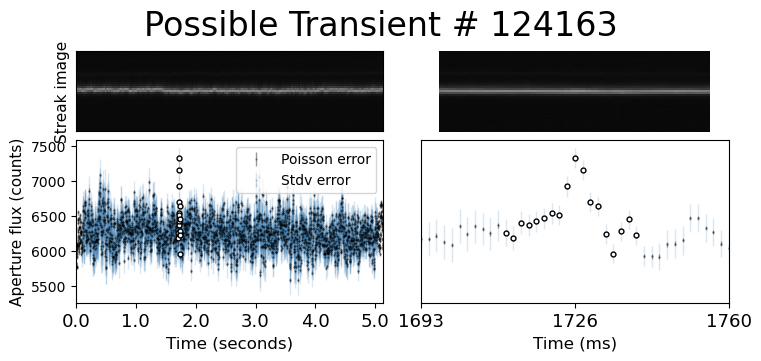

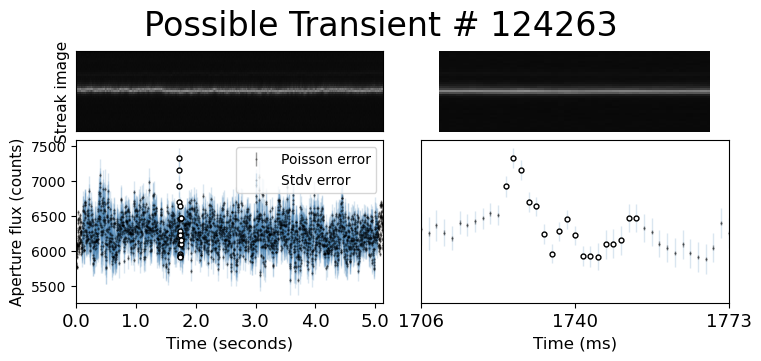

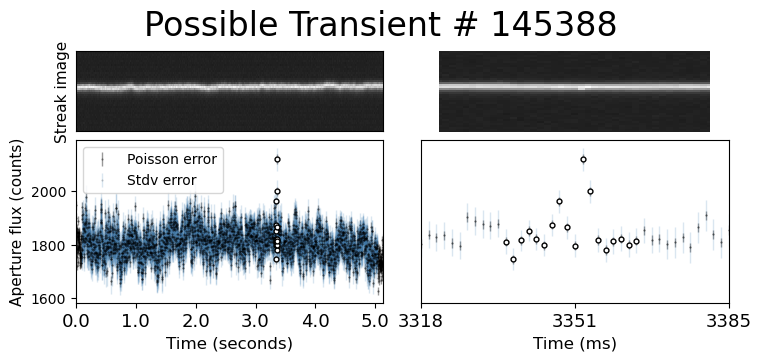

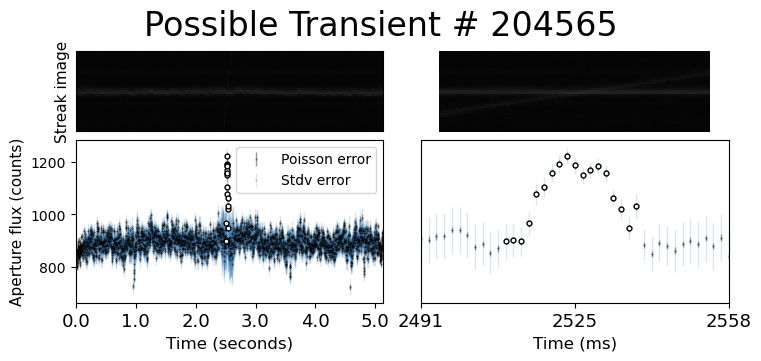

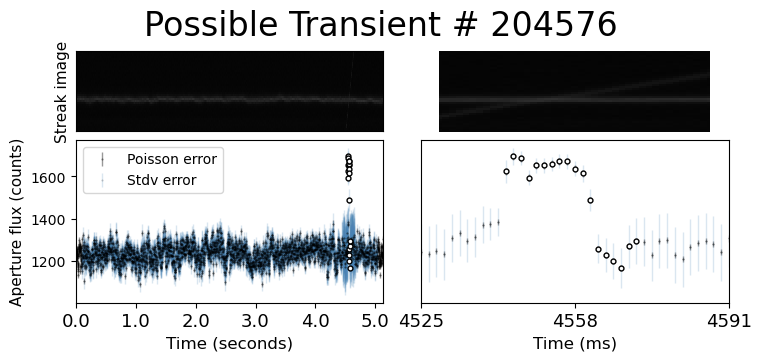

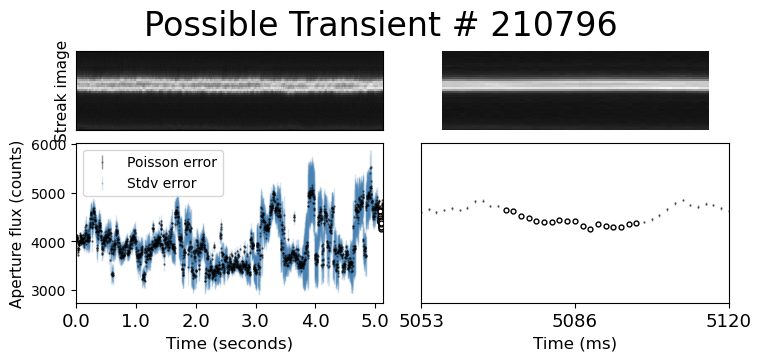

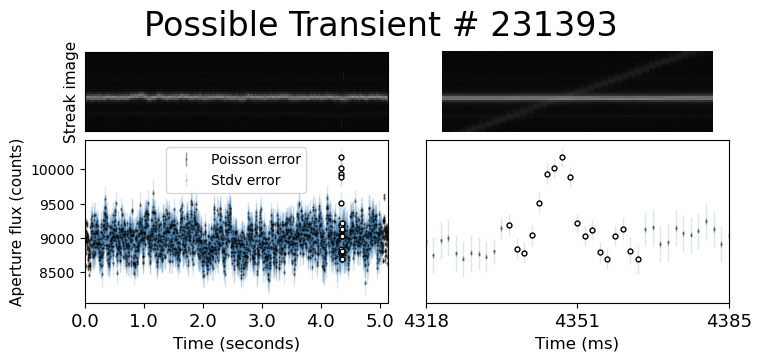

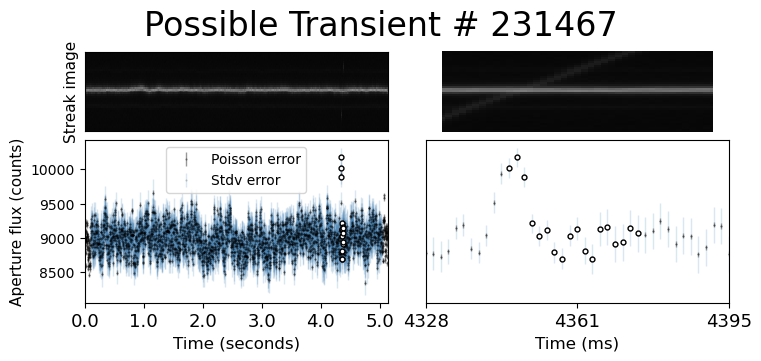

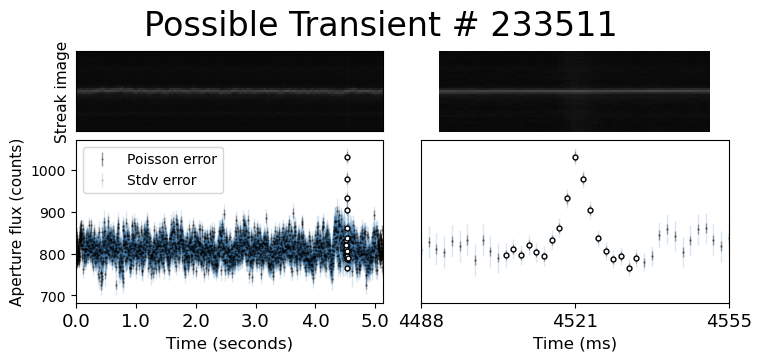

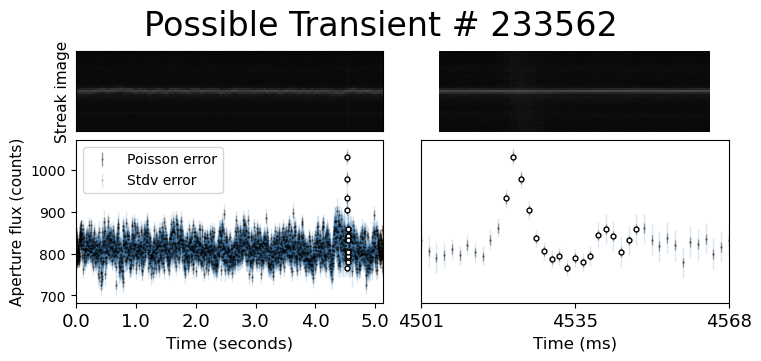

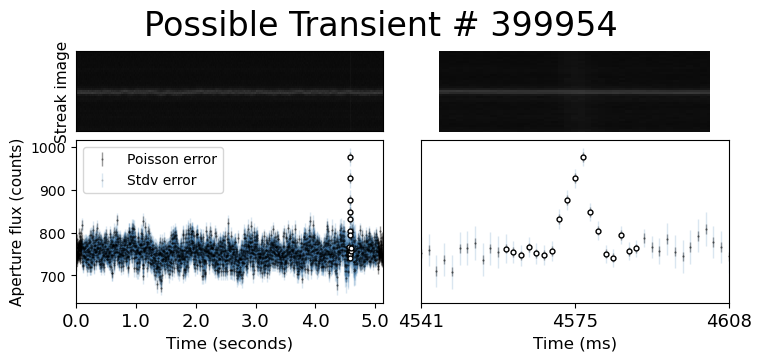

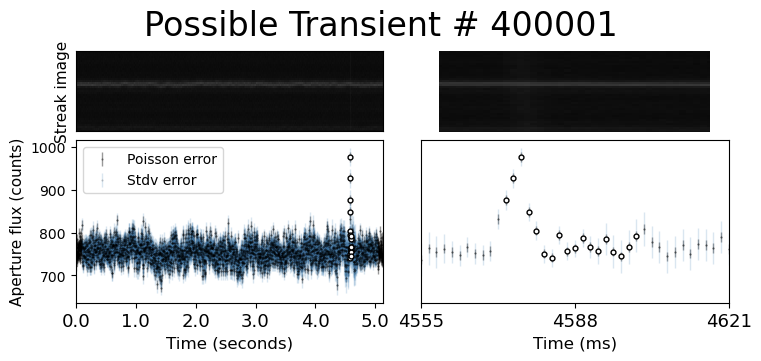

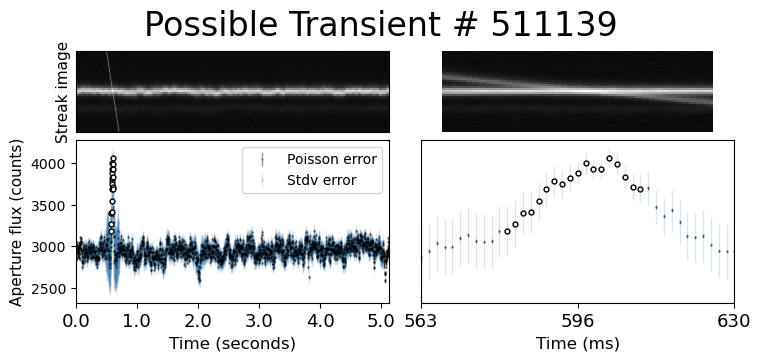

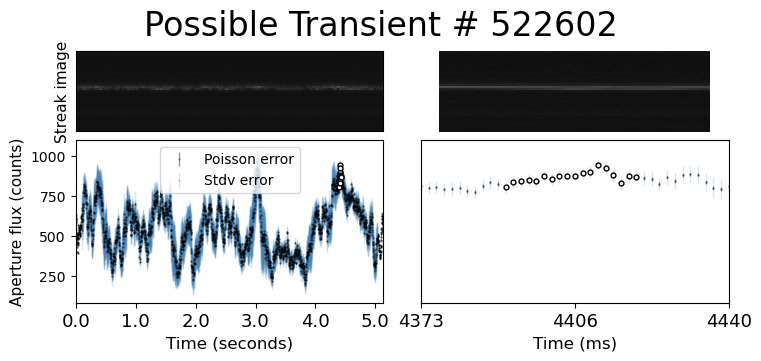

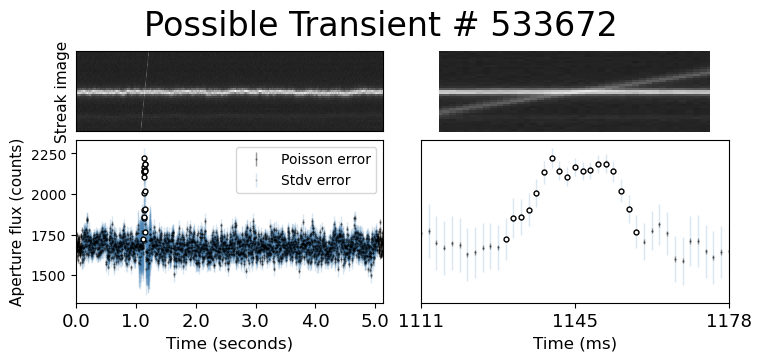

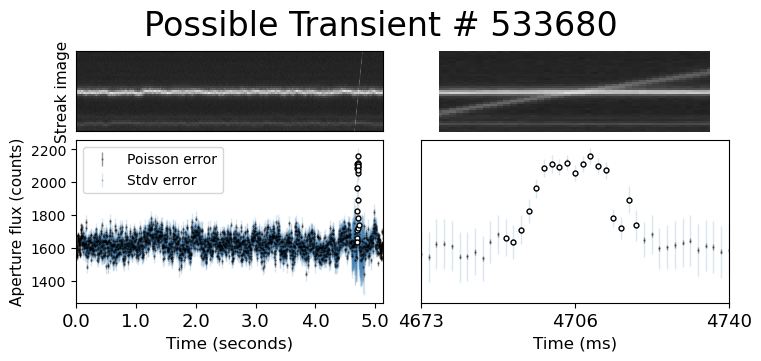

In [84]:
for index in biggest.index:
    rff.plot_time_series_again_aperture(biggest, index)

In [52]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/review_findings_functions.py'>

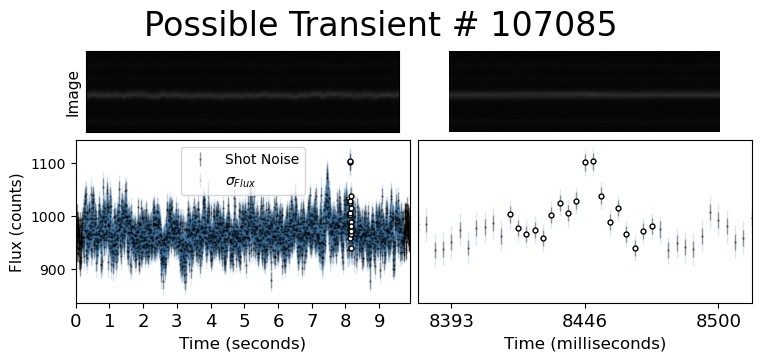

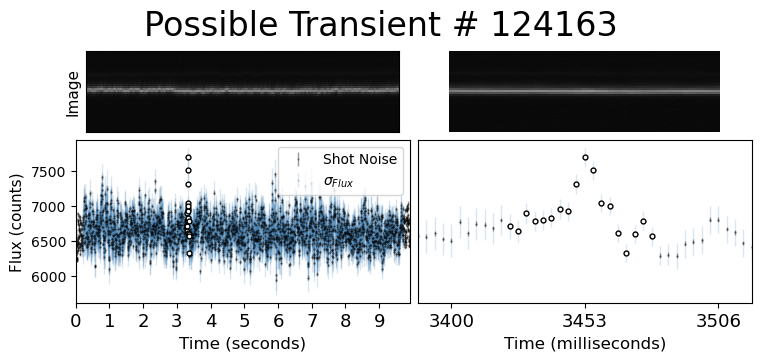

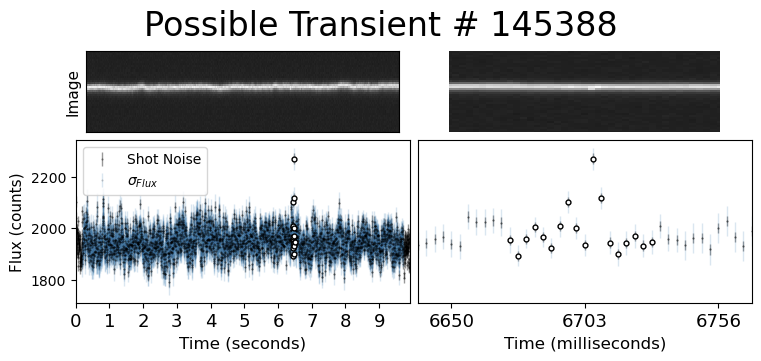

In [57]:
interesting_indices = [107085, 124163,  145388]
for index in interesting_indices:
    rff.plot_time_series_again_aperture(df_lessthan13, index, '1020', 4)

In [116]:
index = interesting_indices[0]
df = df_lessthan13
direcname = '1020'
fname = df.loc[index]["filename"]+"fits.fz"
row = int(df.loc[index]["row_from_nn"])+10
col = int(df.loc[index]["col_from_nn"])+10
quad = int(df.loc[index]["quadrant"])
# if direcname == "0820":
fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"+direcname+"_minus_extras/"
# else:
    # fpath = "/lustre/lrspec/ZTF_data/science_extractions/to_extract/"+direcname+"/"
path = fpath+fname
# print(path)
hdul = fits.open(path)
file1_array = hdul[quad].data
bigstamp = file1_array[row-10:row+10, col-10:col+10]

In [117]:
hdul[0].header

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                  -32 / number of bits per data pixel                  
NAXIS   =                    0 / number of data axes                            
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
ORIGIN  = 'Zwicky Transient Facility' / Data origin                             
OBSERVER= 'ZTF Robotic Observing Software' / Observer                           
ROBOSOFT= '1.1 August 1, 2022' / Robotic software version                       
FITSSOFT= '1.1 August 1, 2022' / FITS software version                          
INSTRUME= 'ZTF/MOSAIC'         / Instrument name                                
DETECTOR= '        '           / Detector controller                            
DETSOFT = '        '        

In [115]:
hdul[0].header

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                  -32 / number of bits per data pixel                  
NAXIS   =                    0 / number of data axes                            
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
ORIGIN  = 'Zwicky Transient Facility' / Data origin                             
OBSERVER= 'ZTF Robotic Observing Software' / Observer                           
ROBOSOFT= '1.1 August 1, 2022' / Robotic software version                       
FITSSOFT= '1.1 August 1, 2022' / FITS software version                          
INSTRUME= 'ZTF/MOSAIC'         / Instrument name                                
DETECTOR= '        '           / Detector controller                            
DETSOFT = '        '        

In [113]:
hdul[0].header

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                  -32 / number of bits per data pixel                  
NAXIS   =                    0 / number of data axes                            
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
ORIGIN  = 'Zwicky Transient Facility' / Data origin                             
OBSERVER= 'ZTF Robotic Observing Software' / Observer                           
ROBOSOFT= '1.1 August 1, 2022' / Robotic software version                       
FITSSOFT= '1.1 August 1, 2022' / FITS software version                          
INSTRUME= 'ZTF/MOSAIC'         / Instrument name                                
DETECTOR= '        '           / Detector controller                            
DETSOFT = '        '        

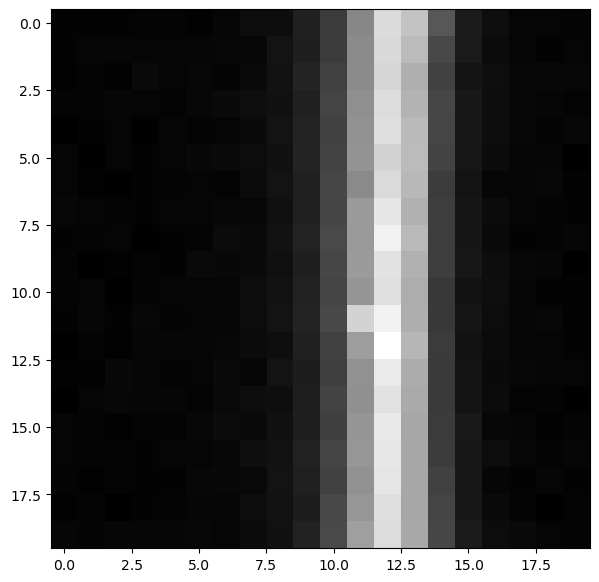

In [112]:
plt.imshow(np.sqrt(bigstamp))

In [120]:
df_lessthan13.loc[interesting_indices[2]]

Unnamed: 0.4                                        145406
Unnamed: 0.3                                             4
Unnamed: 0.2                                             4
Unnamed: 0.1                                            14
Unnamed: 0                                              14
filename          ztf_20221020163819_000640_zg_c06_x_0025.
type                                                   pos
row_from_nn                                    2001.666667
col_from_nn                                    1068.866667
detection_size                                        15.0
quadrant                                                 3
sobel_ratio                                       5.146079
snr_center                                       -0.191538
snr_max                                           7.179645
snr_min                                          -1.354989
Name: 145388, dtype: object

In [118]:
df_lessthan13.loc[interesting_indices[0]]

Unnamed: 0.4                                        107097
Unnamed: 0.3                                            27
Unnamed: 0.2                                            27
Unnamed: 0.1                                           272
Unnamed: 0                                             272
filename          ztf_20221020148032_000686_zg_c16_x_0001.
type                                                   pos
row_from_nn                                    2524.666667
col_from_nn                                     661.266667
detection_size                                        15.0
quadrant                                                 2
sobel_ratio                                       5.355525
snr_center                                        5.936502
snr_max                                           7.108738
snr_min                                          -0.225223
Name: 107085, dtype: object

In [135]:
df_lessthan13.loc[interesting_indices[1]]

Unnamed: 0.4                                        124175
Unnamed: 0.3                                            31
Unnamed: 0.2                                            31
Unnamed: 0.1                                           225
Unnamed: 0                                             225
filename          ztf_20221020157697_000640_zi_c09_x_0025.
type                                                   pos
row_from_nn                                       1026.375
col_from_nn                                      1751.4375
detection_size                                        48.0
quadrant                                                 4
sobel_ratio                                      10.876323
snr_center                                        7.382644
snr_max                                           7.382644
snr_min                                          -2.223329
Name: 124163, dtype: object

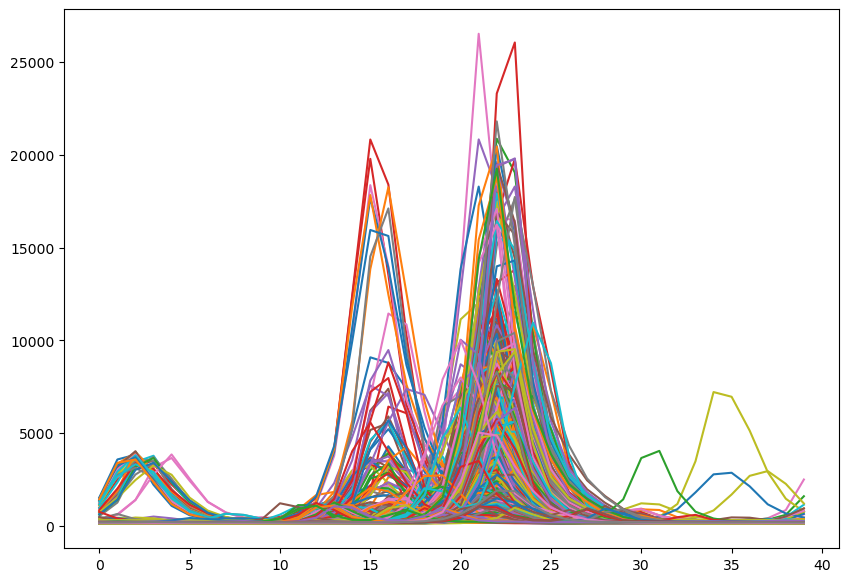

In [122]:
to_drop_neg = []
for index in df_lessthan13_morethanfive_neg_cleaned.index:
    if has_two_streaks(df_lessthan13_morethanfive_neg_cleaned, index):
        to_drop_neg.append(index)
    # if len(to_drop)==5:
    #     break

In [123]:
df_lessthan13_morethanfive_neg_cleaned_onestreak = df_lessthan13_morethanfive_neg_cleaned.drop(to_drop_neg)

In [128]:
dimmest = df_lessthan13_morethanfive_neg_cleaned_onestreak[df_lessthan13_morethanfive_neg_cleaned_onestreak['snr_min']<-8]

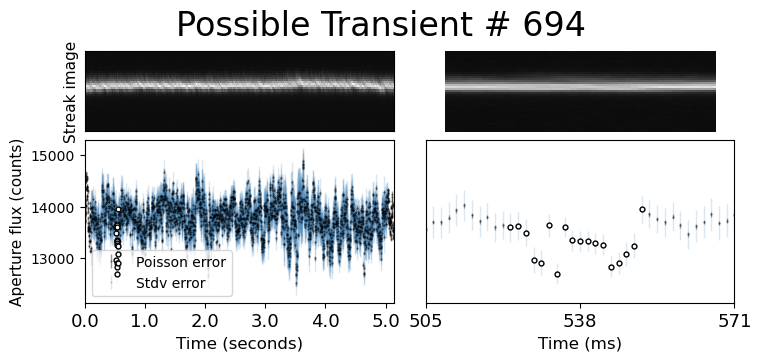

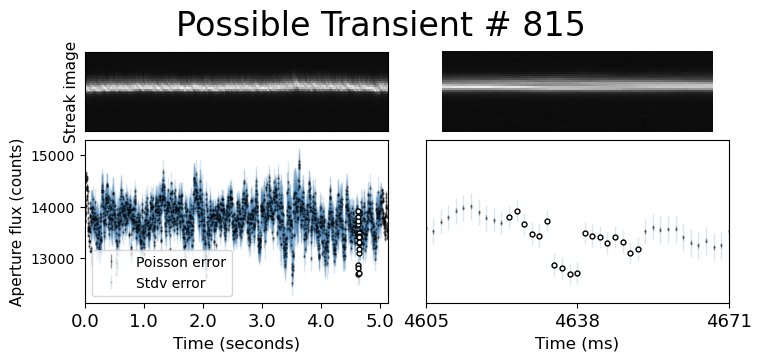

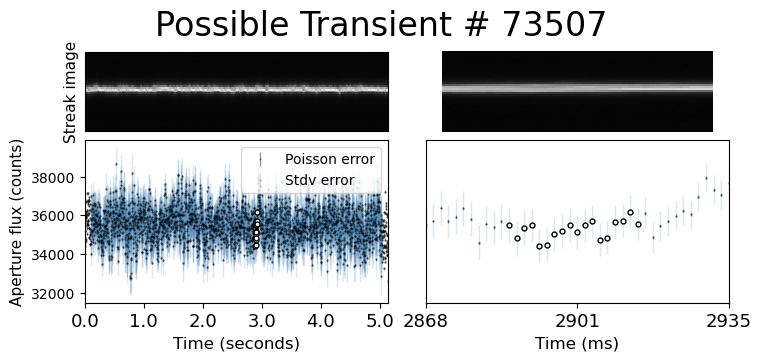

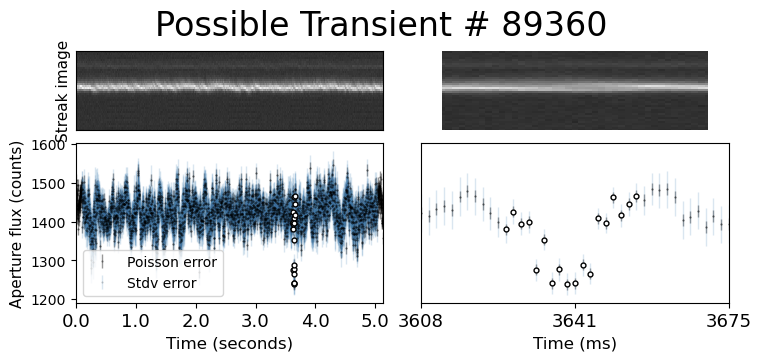

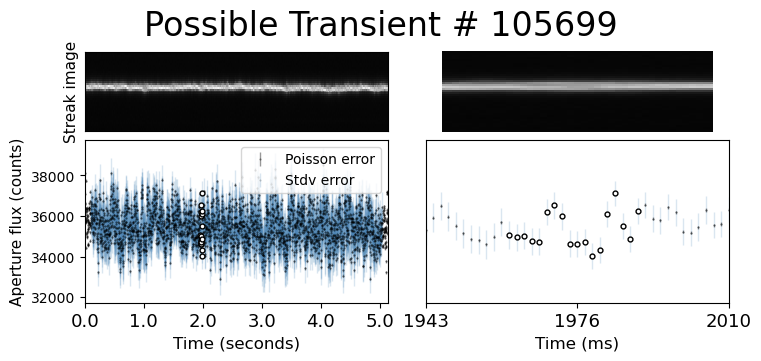

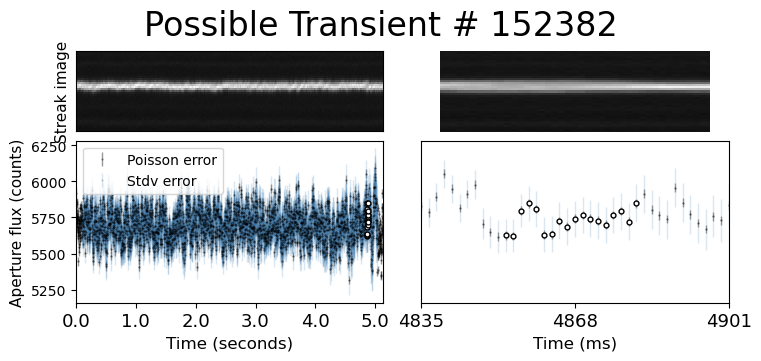

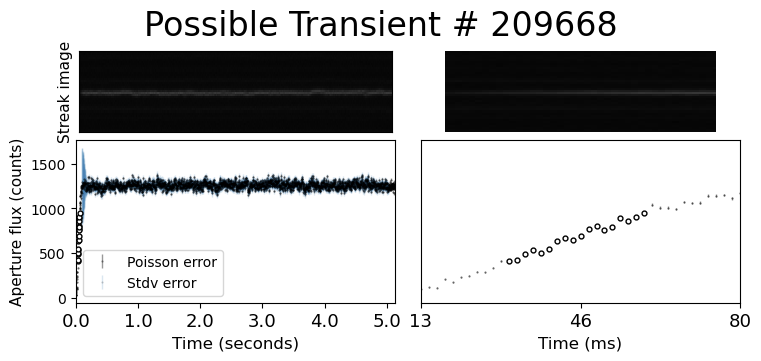

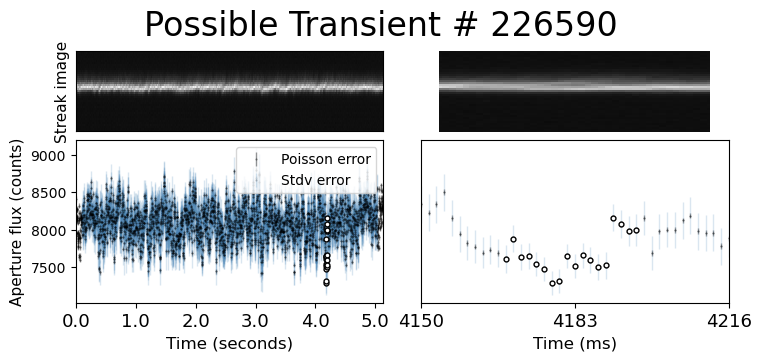

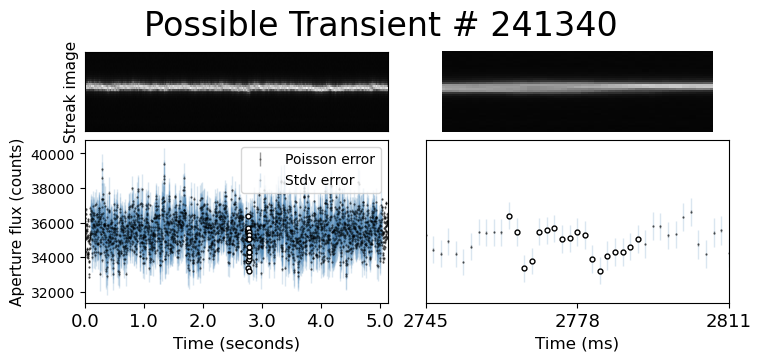

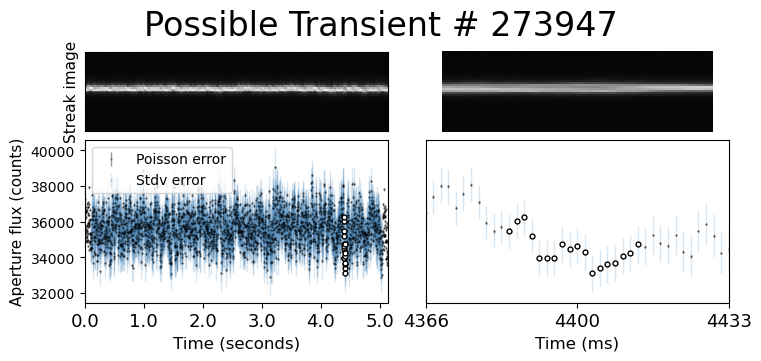

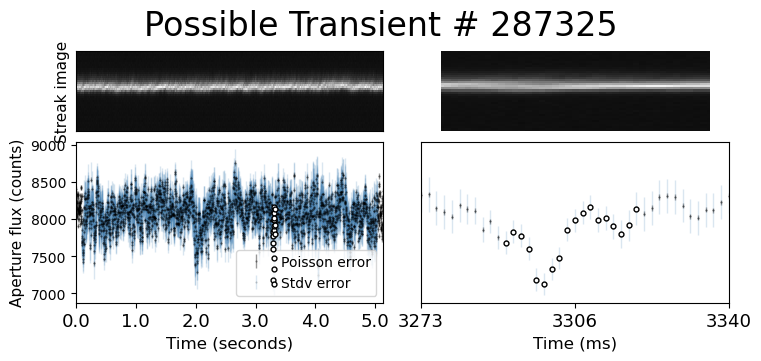

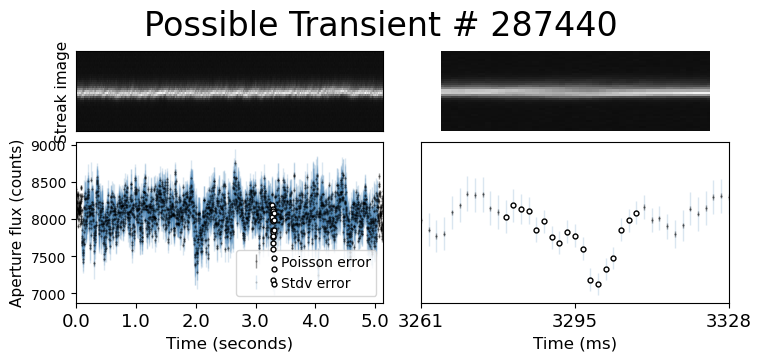

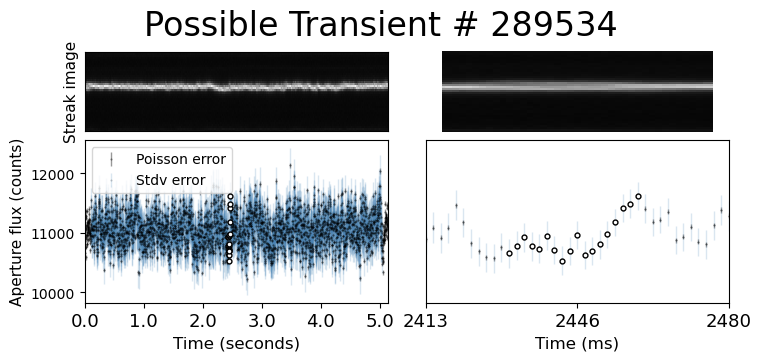

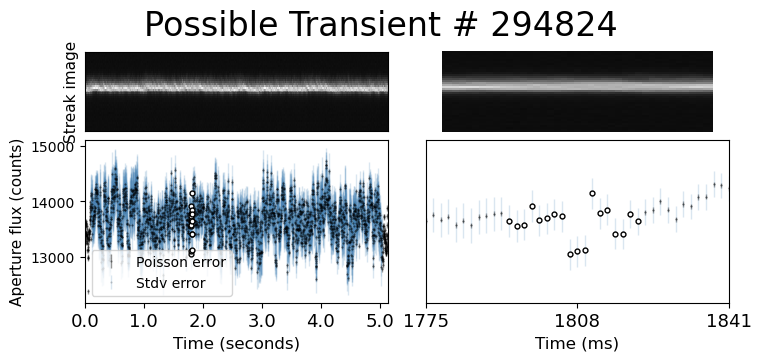

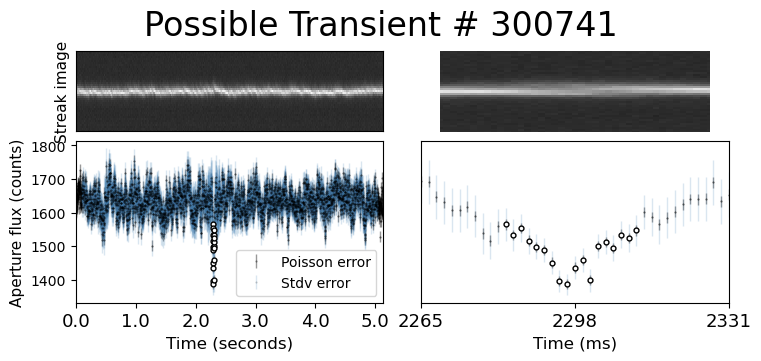

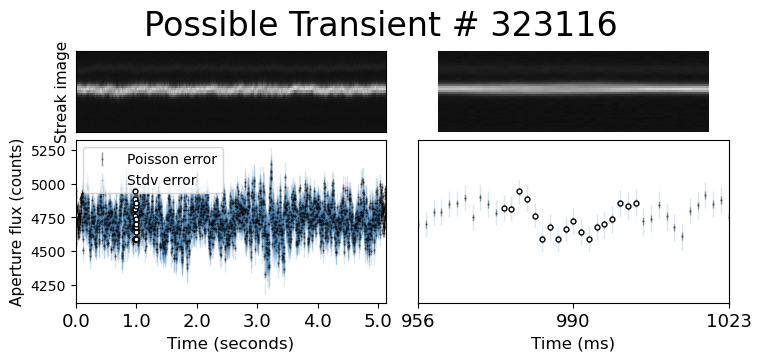

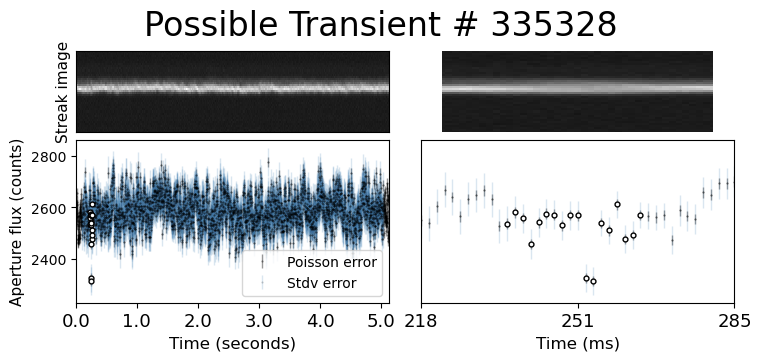

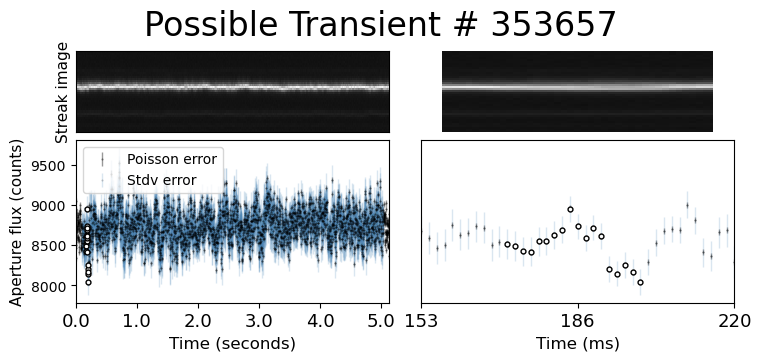

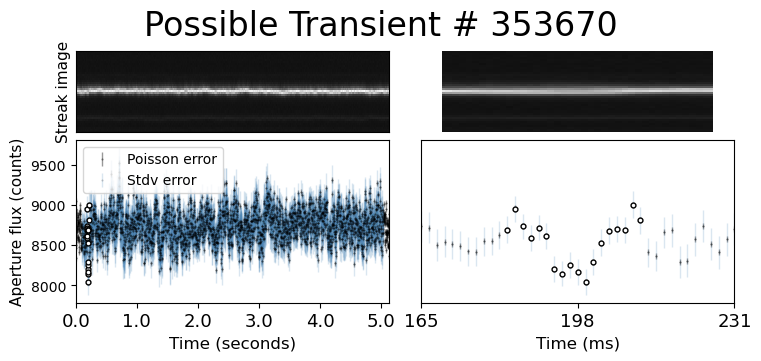

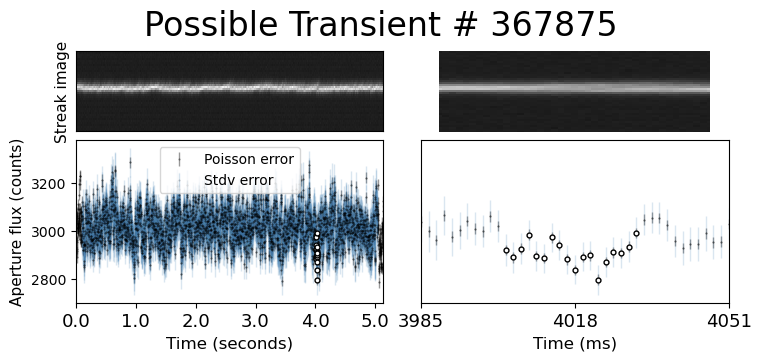

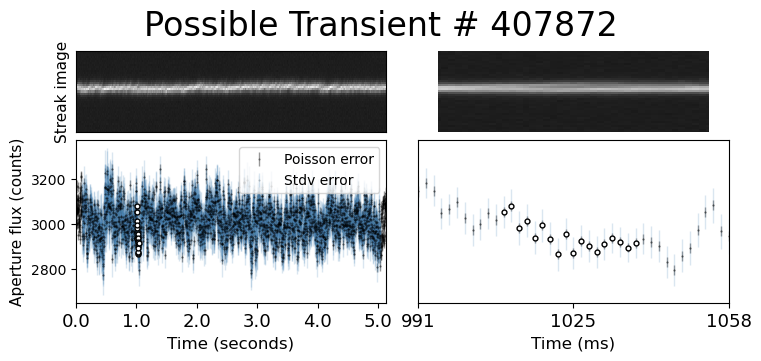

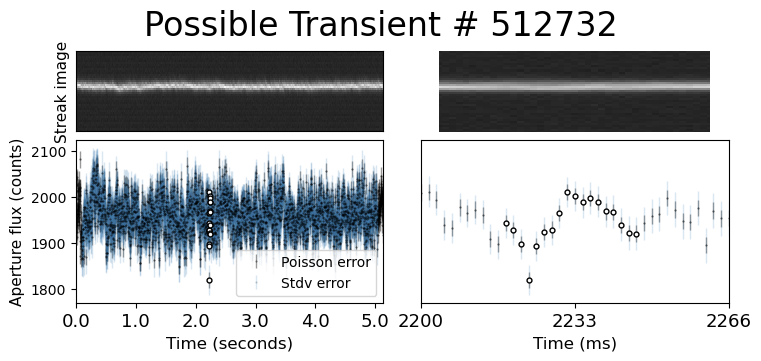

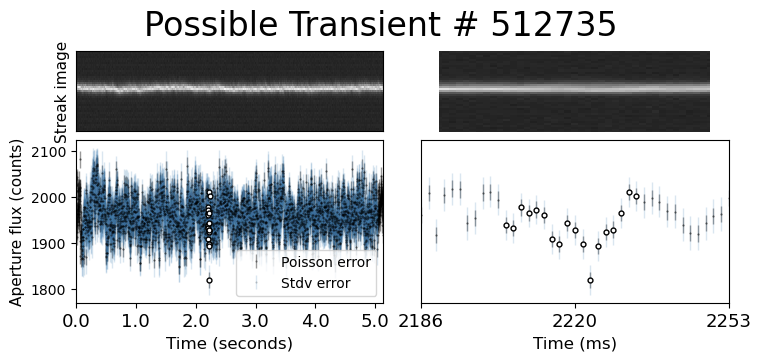

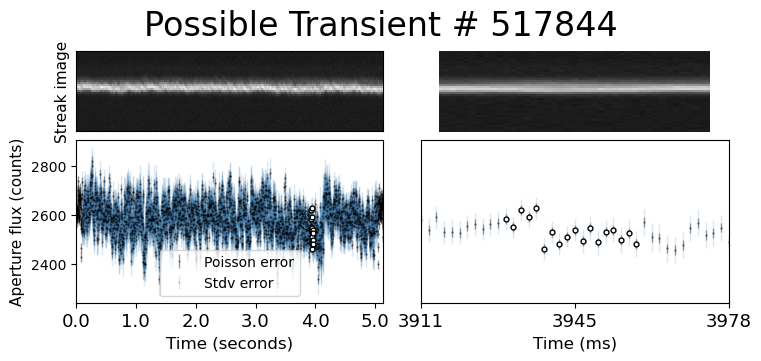

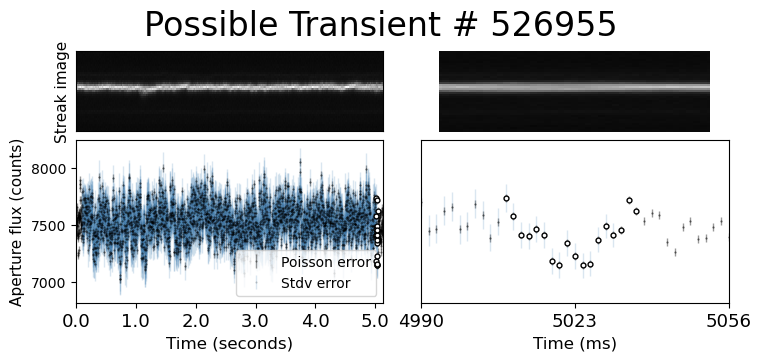

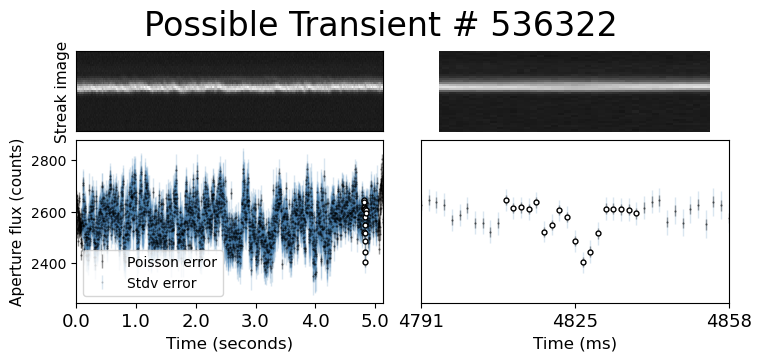

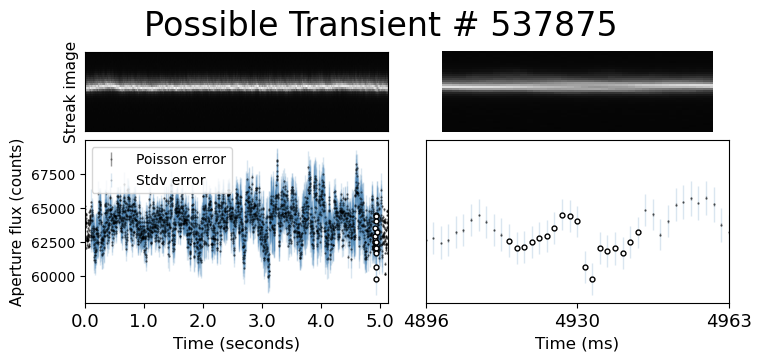

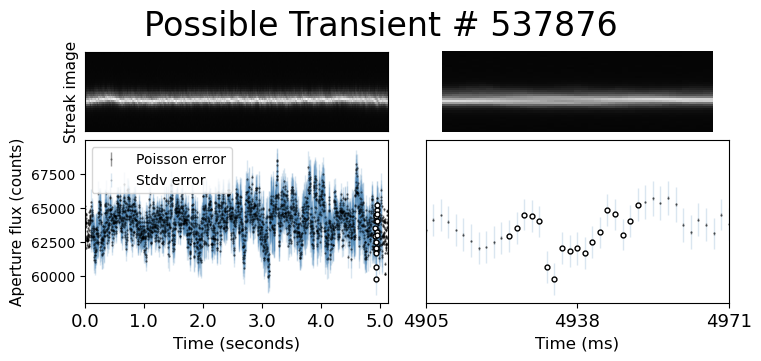

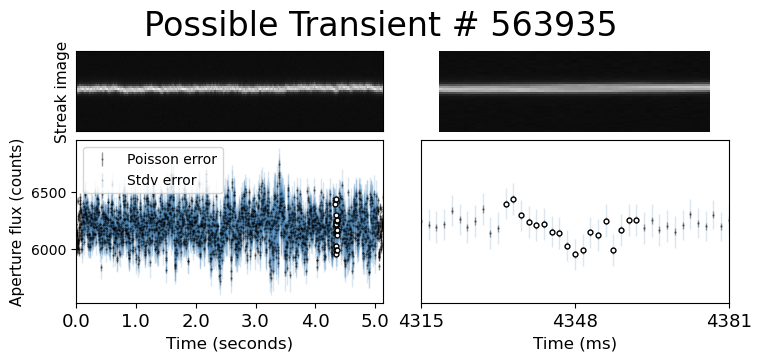

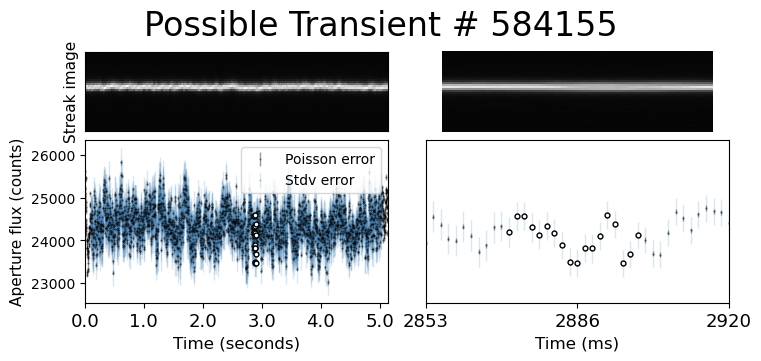

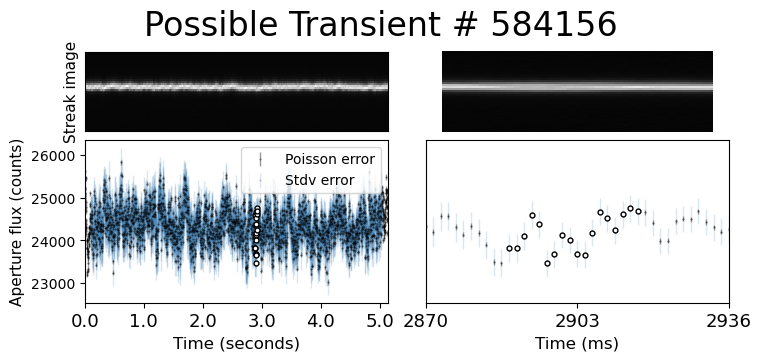

In [130]:
for index in dimmest.index:
    rff.plot_time_series_again_aperture(dimmest, index, '1020', 4)

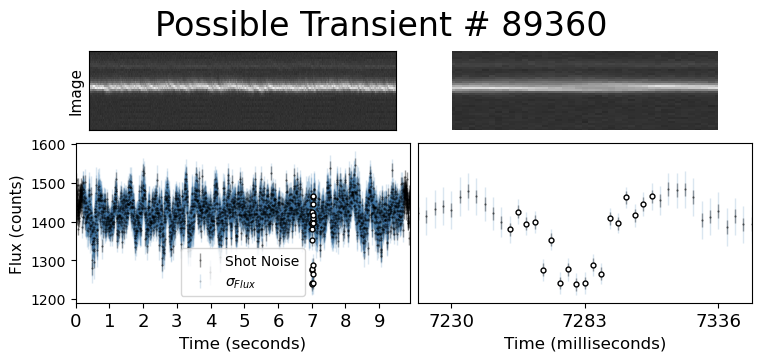

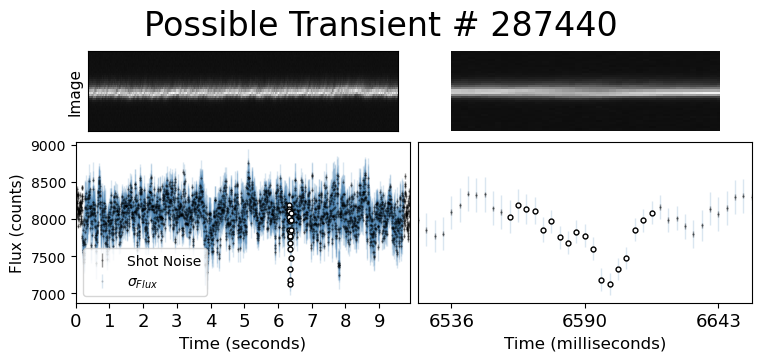

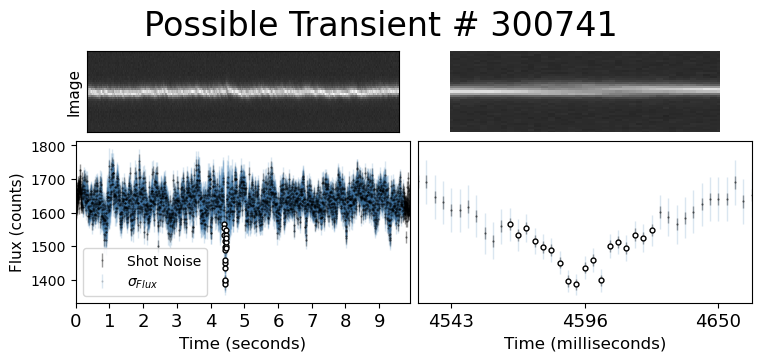

In [58]:
for index in [89360,287440, 300741]:
    rff.plot_time_series_again_aperture(df_lessthan13, index, '1020', 4, True)

In [23]:
importlib.reload(rff)

<module 'review_findings_functions' from '/home/3155/review_findings_functions.py'>

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c14_x_0017.fits.fz


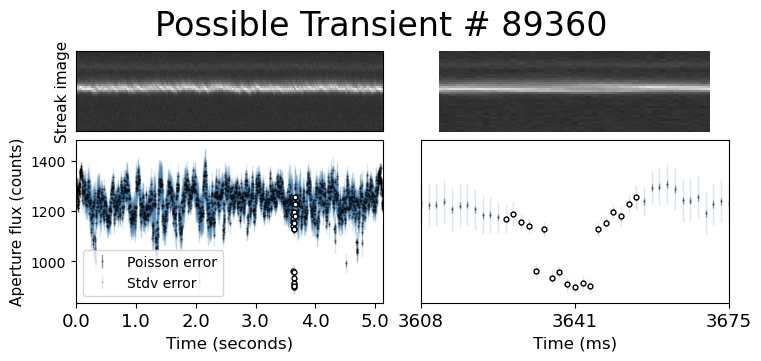

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0017.fits.fz


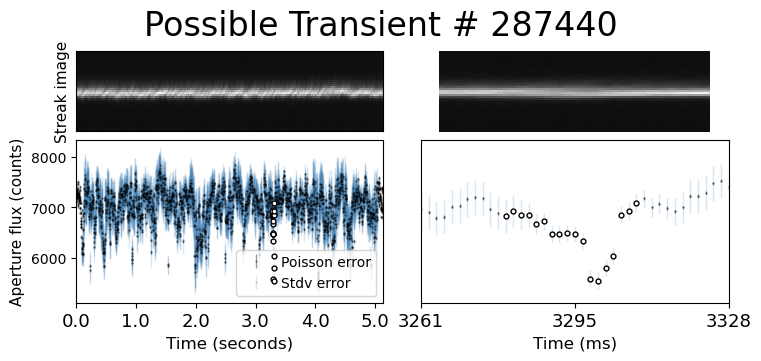

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020297847_000449_zr_c09_x_0016.fits.fz


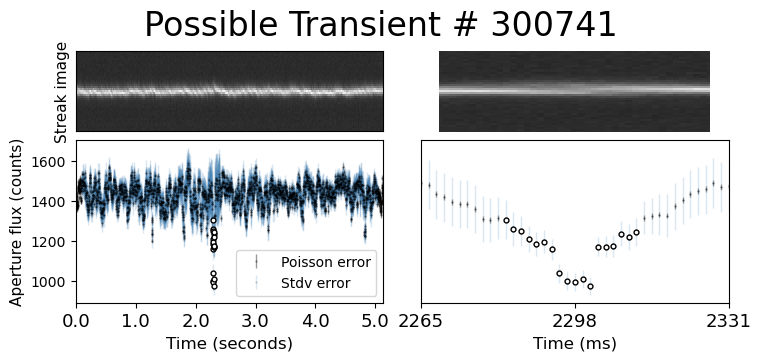

In [26]:
for index in [89360,287440, 300741]:
    rff.plot_time_series_again_aperture(df_lessthan13, index, '1020', 2, tracking=True)

In [29]:
best_dim = df_lessthan13.loc[[89360,287440, 300741]]

In [37]:
importlib.reload(fitting)

<module 'fitting' from '/home/3155/fitting.py'>

In [38]:
best_dim_fit = fitting.fit_df(best_dim, form=fits, fpath="/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/")

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c14_x_0017.fits.fz
2185 3.872983346207417 0.7277961704542496 1237.3630588644803
2183.7160448108775 3.135755094538319 0.7180541552121051 1234.5015404904677 3045.853021345353
/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020294271_000449_zr_c13_x_0017.fits.fz
1977 7.0710678118654755 0.9037732323793134 7151.087996983292
1977.0 7.0710678118654755 0.9037732323793134 7151.087996983292 17675.71463637894
/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020297847_000449_zr_c09_x_0016.fits.fz
1379 2.449489742783178 0.690527837229648 1439.8177731957767
1378.877744897705 6.9039635947614455 0.7525831419424529 1446.4446747455233 3627.522088210826


In [39]:
best_dim_fit

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min,optimized_M,optimized_sig,optimized_A,optimized_streak_val,min_val
89360,89370,13,13,51,51,ztf_20221020294271_000449_zr_c14_x_0017.,neg,2175.80,696.866667,15.0,1,12.111379,-11.521632,0.498704,-11.521632,2183.716045,3.135755,0.718054,1234.501540,3045.853021
287440,287476,152,152,271,271,ztf_20221020294271_000449_zr_c13_x_0017.,neg,1967.98,2539.740000,50.0,4,9.582685,-3.457538,0.961594,-9.138141,1977.000000,7.071068,0.903773,7151.087997,17675.714636
300741,300781,10,10,29,29,ztf_20221020297847_000449_zr_c09_x_0016.,neg,1369.50,3037.000000,6.0,2,9.324155,-9.710698,-2.559199,-10.199664,1378.877745,6.903964,0.752583,1446.444675,3627.522088


In [ ]:
interesting_indices = [107085, 124163,  145388]
for index in interesting_indices:
    rff.plot_time_series_again_aperture(df_lessthan13, index, '1020', 4)

In [41]:
best_bri = df_lessthan13.loc[[107085, 124163,  145388]]
best_bri_fit = fitting.fit_df(best_bri, form=fits, fpath="/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/")

/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020148032_000686_zg_c16_x_0001.fits.fz
2534 3.872983346207417 1.1276283951508113 902.7959165667544
2534.7064885366494 1.1446325704767188 1.1551928538945184 903.7509407813207 1926.9330608211865
/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020157697_000640_zi_c09_x_0025.fits.fz
1036 6.928203230275509 1.1774232530066124 6223.872186339728
1035.9991164449593 2.1882544534847796 1.12432091180099 6232.839116944333 15011.8051466749
/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/
ztf_20221020163819_000640_zg_c06_x_0025.fits.fz
2011 3.872983346207417 0.9823255178190498 1828.1376808090965
2008.9483738645026 0.6560530432651491 1.073458048685963 1826.3439391027869 4282.517309556864


In [42]:
best_bri_fit

,Unnamed: 0.4,Unnamed: 0.3,Unnamed: 0.2,Unnamed: 0.1,Unnamed: 0,filename,type,row_from_nn,col_from_nn,detection_size,quadrant,sobel_ratio,snr_center,snr_max,snr_min,optimized_M,optimized_sig,optimized_A,optimized_streak_val,min_val
107085,107097,27,27,272,272,ztf_20221020148032_000686_zg_c16_x_0001.,pos,2524.666667,661.266667,15.0,2,5.355525,5.936502,7.108738,-0.225223,2534.706489,1.144633,1.155193,903.750941,1926.933061
124163,124175,31,31,225,225,ztf_20221020157697_000640_zi_c09_x_0025.,pos,1026.375000,1751.437500,48.0,4,10.876323,7.382644,7.382644,-2.223329,1035.999116,2.188254,1.124321,6232.839117,15011.805147
145388,145406,4,4,14,14,ztf_20221020163819_000640_zg_c06_x_0025.,pos,2001.666667,1068.866667,15.0,3,5.146079,-0.191538,7.179645,-1.354989,2008.948374,0.656053,1.073458,1826.343939,4282.517310


In [45]:
fpath = '/lustre/lrspec/ZTF_data/science_extractions/to_extract/1020_minus_extras/'

In [46]:
hdul = fits.open(fpath+'ztf_20221020148032_000686_zg_c16_x_0001.fits.fz')

In [49]:
hdul[0].header

SIMPLE  =                    T / file does conform to FITS standard             
BITPIX  =                  -32 / number of bits per data pixel                  
NAXIS   =                    0 / number of data axes                            
EXTEND  =                    T / FITS dataset may contain extensions            
COMMENT   FITS (Flexible Image Transport System) format is defined in 'Astronomy
COMMENT   and Astrophysics', volume 376, page 359; bibcode: 2001A&A...376..359H 
ORIGIN  = 'Zwicky Transient Facility' / Data origin                             
OBSERVER= 'ZTF Robotic Observing Software' / Observer                           
ROBOSOFT= '1.1 August 1, 2022' / Robotic software version                       
FITSSOFT= '1.1 August 1, 2022' / FITS software version                          
INSTRUME= 'ZTF/MOSAIC'         / Instrument name                                
DETECTOR= '        '           / Detector controller                            
DETSOFT = '        '        